Блокнот скачивает файлы из общедоступной папки Google Drive

In [1]:
!pip -q install gdown timm grad-cam gradio

import os, sys, json, shutil
from pathlib import Path
import gdown

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 3.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Потребуется примерно 3 минуты для выполнения следующего блока

In [3]:
DRIVE_FOLDER_URL = "https://drive.google.com/drive/folders/1iY-Mh5xX4aaaTrrgrOahCgcMe4MThlPj?usp=sharing"



if not DRIVE_FOLDER_URL.startswith("https://drive.google.com/"):
    raise ValueError("Вставьте ссылку на папку Google Drive в переменную DRIVE_FOLDER_URL.")

PROJECT_DIR = Path("/content/M2050")
if PROJECT_DIR.exists():
    shutil.rmtree(PROJECT_DIR)

print("Скачиваю папку M2050 из Google Drive. Для папки размером около 2,8 ГБ это может занять некоторое время...")
result = gdown.download_folder(
    url=DRIVE_FOLDER_URL,
    output=str(PROJECT_DIR),
    quiet=False,
    use_cookies=False,
    remaining_ok=True
)
if not result:
    raise RuntimeError(
        "Не удалось скачать папку. Проверьте, что доступ установлен как "
        "«Все, у кого есть ссылка», и что вставлена именно ссылка на папку."
    )

RUN = "convnext_tiny_base"
W = PROJECT_DIR / "weights" / RUN
required = [
    W / "model_state.pt",
    W / "config.json",
    PROJECT_DIR / "brain-mri-tumor.zip",
    PROJECT_DIR / "data" / "splits_v3.csv",
    PROJECT_DIR / "data" / "cache_256_v4.npy",
    PROJECT_DIR / "data" / "dataset.zip",
]
missing = [str(p) for p in required if not p.exists()]
if missing:
    raise FileNotFoundError(
        "В скачанной папке M2050 не найдены обязательные файлы:\\n- "
        + "\\n- ".join(missing)
        + "\\nПроверьте структуру папки в Google Drive."
    )

!unzip -q -o "{PROJECT_DIR}/brain-mri-tumor.zip" -d /content
sys.path.insert(0, "/content/brain-mri-tumor/src")
sys.path.insert(0, "/content/brain-mri-tumor/app")
for k in [k for k in sys.modules if k.startswith("brainmri") or k == "gradio_app"]:
    del sys.modules[k]

# Исходные картинки нужны для примеров в интерфейсе.
LOCAL_DATA = Path("/content/data")
if not LOCAL_DATA.exists():
    LOCAL_DATA.mkdir(parents=True)
    !unzip -q "{PROJECT_DIR}/data/dataset.zip" -d "{LOCAL_DATA}"
    !rm -rf /content/data/__MACOSX
    !find /content/data -name '._*' -delete

import numpy as np, pandas as pd, torch
from brainmri.infer import Predictor
from brainmri.serving import fit_reference, nn_distance
from brainmri.data.preprocess import center_eval

sp = pd.read_csv(PROJECT_DIR / "data" / "splits_v3.csv")
sp["aug"] = sp["aug"].fillna("UNK").replace({"NA": "UNK"})
X = np.load(PROJECT_DIR / "data" / "cache_256_v4.npy")
assert len(X) == len(sp), f"Несовпадение: cache содержит {len(X)} записей, splits — {len(sp)}"

P = Predictor(W)
cls2id = {c: i for i, c in enumerate(P.classes)}
print("Модель загружена, устройство:", P.device, "| классы:", P.classes)


Скачиваю папку M2050 из Google Drive. Для папки размером около 2,8 ГБ это может занять некоторое время...


Retrieving folder contents


Retrieving folder 1ED8X3lz5pp_TDr86kp3FIwENSkAKiDWH checkpoints
Retrieving folder 1FTuKIDW4dPPsZoyMw5z-LYsRKIXlgS0K convnext_tiny_base
Processing file 1dB8ENQ09tPGfmMBFJtz6m0b03JdvBzwv best.pt
Processing file 1NocUMnn0A-QBviyq8KbnUA-1O2UPrCBX history.csv
Processing file 1CsrQK5tvjtRMWAO1NDM51t9keI7vNby4 last.pt
Retrieving folder 1JDQmcGOL1JZUDgRLgF4n0EcN2_wID8c8 smoke
Processing file 1L6e5lGx9ZdrazBXkBEyLn07rtdfcZldZ best.pt
Processing file 1YhV0i-n77jNkKaKvI5_r6fh4Rpuj_y5I history.csv
Processing file 1rOo-Hy7dLTzeadmTF0v8v073kvNiLkby last.pt
Retrieving folder 1fAREo0sCu6qY2t09mxGvoEIBzdUtUjHC data
Processing file 1kZhvYzp6jve8BUUzV-WSzdpWp7EOPDYH cache_256_v3.npy
Processing file 1NMUeis2lvWTZ_ZEFPs4gPD6gO1dXxAmK cache_256_v4.npy
Processing file 1uZFWgk1hyTOex4HVIOmW9BMi50TF6iAE dataset.zip
Processing file 1DfuJ2f4lFJB0AkqSK-rFhUfWWqHEmqhQ dhash16.npy
Processing file 1TVIKTTGNrWXXQ7nCfeaQQll0iXfQ40Uz manifest.csv
Processing file 1HNhsba5h0eiaLPbnfTEvA4fKLD4PwZV1 shortcut_map_v4.csv
Pro

 53%|█████▎    | 419M/791M [00:15<00:02, 154MB/s]

Processing file 1sGnzWA0tSSO8ktftGLH1umJ4OynQXKzn config.json
Processing file 1VFYhSxjNRp3FpoXTRErLkheAYzpDAbnh model_state.pt
Processing file 16Xp8ZRGxXCp4Zy1QPVOS29WWaKEadAqW prototype_config.json
Processing file 1lyoLqSYsOgAXhmkrPm2ktNVRPwBciosn reference_bank.npz
Processing file 1-klWf1PJmf50WzTJ0VjGdmPLmOJZp1Lw как_использовать.txt
Retrieving folder 12slVOx1Xr9HG1332TPjWyt3dYUKR6GnY smoke
Processing file 1yZQq-EF2j4dnmDYaapHV91GyIrMQwm1q config.json
Processing file 1NJZc5bYWp_sPJ_5fosn5zxTCgRzpriR9 model_state.pt
Processing file 1YR0OMbSmDrLnTBkohOTiHQ0jeuC9p0-J как_использовать.txt
Processing file 15yA4FCVdpFnCgwa3mPY4N3LHPSz-Kk0h brain-mri-tumor.zip


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.google.com/uc?id=1dB8ENQ09tPGfmMBFJtz6m0b03JdvBzwv
From (redirected): https://drive.google.com/uc?id=1dB8ENQ09tPGfmMBFJtz6m0b03JdvBzwv&confirm=t&uuid=b59755c7-c371-46bd-b2b5-8ce9993e59ba
To: /content/M2050/checkpoints/convnext_tiny_base/best.pt

  0%|          | 0.00/111M [00:00<?, ?B/s]
  6%|▌         | 6.82M/111M [00:00<00:02, 49.5MB/s]
 24%|██▍       | 27.3M/111M [00:00<00:00, 128MB/s] 
 37%|███▋      | 41.4M/111M [00:00<00:00, 90.9MB/s]
 47%|████▋     | 52.4M/111M [00:00<00:00, 83.5MB/s]
 56%|█████▌    | 61.9M/111M [00:00<00:00, 73.0MB/s]
 72%|███████▏  | 80.2M/111M [00:00<00:00, 80.1MB/s]
 86%|████████▌ | 95.4M/111M [00:01<00:00, 95.6MB/s]
100%|██████████| 111M/111M [00:01<00:00, 83.3MB/s]
Downloading...
From: https://drive.google.com/uc?id=1NocUMnn0A-QBviyq8KbnUA-1O2UPrCBX
To: /content/M2050/checkpoints/convnext_tiny_base/history.c

Модель загружена, устройство: cuda | классы: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [4]:
@torch.no_grad()
def feats_probs(idxs, bs=64):
    P.model.eval()
    probs, feats = [], []
    for s in range(0, len(idxs), bs):
        b = np.stack([center_eval(X[i]) for i in idxs[s:s + bs]])
        xb = torch.from_numpy(((b - P.mean) / P.std).astype(np.float32))[:, None].to(P.device)
        f = P.model.forward_features(xb)
        feats.append(P.model.forward_head(f, pre_logits=True).float().cpu().numpy())
        probs.append(P.model.forward_head(f).float().softmax(1).cpu().numpy())
    return np.concatenate(probs), np.concatenate(feats)

tr = sp[(sp.role == 'train') & sp.eval_rep]
va = sp[(sp.role == 'val') & sp.eval_rep]
te = sp[(sp.role == 'test') & sp.eval_rep]
_, f_tr = feats_probs(tr.index.values)
mean, bank = fit_reference(f_tr)
print('опорный набор:', bank.shape)

p_va, f_va = feats_probs(va.index.values)
p_te, f_te = feats_probs(te.index.values)
conf_va, conf_te = p_va.max(1), p_te.max(1)
dist_va, dist_te = nn_distance(f_va, mean, bank), nn_distance(f_te, mean, bank)
correct_te = p_te.argmax(1) == te.cls.map(cls2id).values
print('test: снимков', len(te), '| точность', round(float(correct_te.mean()), 4), '| ошибок', int((~correct_te).sum()))

t_conf = float(np.quantile(conf_va, 0.02))

def flag_stats(t_c, t_d):
    flagged = (conf_te < t_c) | (dist_te > t_d)
    return dict(отмечено_доля=round(float(flagged.mean()), 3),
                acc_без_отметки=round(float(correct_te[~flagged].mean()), 4),
                acc_с_отметкой=round(float(correct_te[flagged].mean()), 4) if flagged.any() else None,
                ошибок_всего=int((~correct_te).sum()), ошибок_в_отмеченных=int((~correct_te & flagged).sum()))

rows = [dict(DIST_Q='только уверенность', **flag_stats(t_conf, np.inf))]
for q in [0.7, 0.8, 0.9, 0.95]:
    rows.append(dict(DIST_Q=q, **flag_stats(t_conf, float(np.quantile(dist_va, q)))))
print('порог уверенности (из val):', round(t_conf, 4))
print(pd.DataFrame(rows).to_string(index=False))

опорный набор: (3502, 768)
test: снимков 751 | точность 0.9854 | ошибок 11
порог уверенности (из val): 0.8936
            DIST_Q  отмечено_доля  acc_без_отметки  acc_с_отметкой  ошибок_всего  ошибок_в_отмеченных
только уверенность          0.019           0.9946          0.5000            11                    7
               0.7          0.261           0.9982          0.9490            11                   10
               0.8          0.182           0.9984          0.9270            11                   10
               0.9          0.095           0.9971          0.8732            11                    9
              0.95          0.043           0.9958          0.7500            11                    8


In [5]:
DIST_Q = 0.9
t_dist = float(np.quantile(dist_va, DIST_Q))
st = flag_stats(t_conf, t_dist)
print('итоговые пороги: уверенность <', round(t_conf, 4), '| непохожесть >', round(t_dist, 4))
print('на test:', st)

np.savez_compressed(W / 'reference_bank.npz', mean=mean, bank=bank)
json.dump(dict(t_conf=t_conf, t_dist=t_dist, dist_q=DIST_Q, conf_q=0.02,
               note='Пороги выбраны по val, оценены на test. Уверенность занижена из-за сглаживания меток при обучении.',
               test_check=st), open(W / 'prototype_config.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1)
print('сохранено в', W, sorted(os.listdir(W)))
P = Predictor(W)      # перезагружаем с новыми порогами и опорным набором

итоговые пороги: уверенность < 0.8936 | непохожесть > 0.0043
на test: {'отмечено_доля': 0.095, 'acc_без_отметки': 0.9971, 'acc_с_отметкой': 0.8732, 'ошибок_всего': 11, 'ошибок_в_отмеченных': 9}
сохранено в /content/M2050/weights/convnext_tiny_base ['config.json', 'model_state.pt', 'prototype_config.json', 'reference_bank.npz', 'как_использовать.txt']


--- glioma: **🟢 Типичный случай.** Уверенность выше порога, снимок похож на обучающие данные.
--- meningioma: **🟢 Типичный случай.** Уверенность выше порога, снимок похож на обучающие данные.
--- notumor: **🟢 Типичный случай.** Уверенность выше порога, снимок похож на обучающие данные.
--- pituitary: **🟢 Типичный случай.** Уверенность выше порога, снимок похож на обучающие данные.
--- glioma: **🔴 Низкое доверие.** Модель не уверена, и снимок нетипичен для обучающих данных (другой источник, протокол или качество


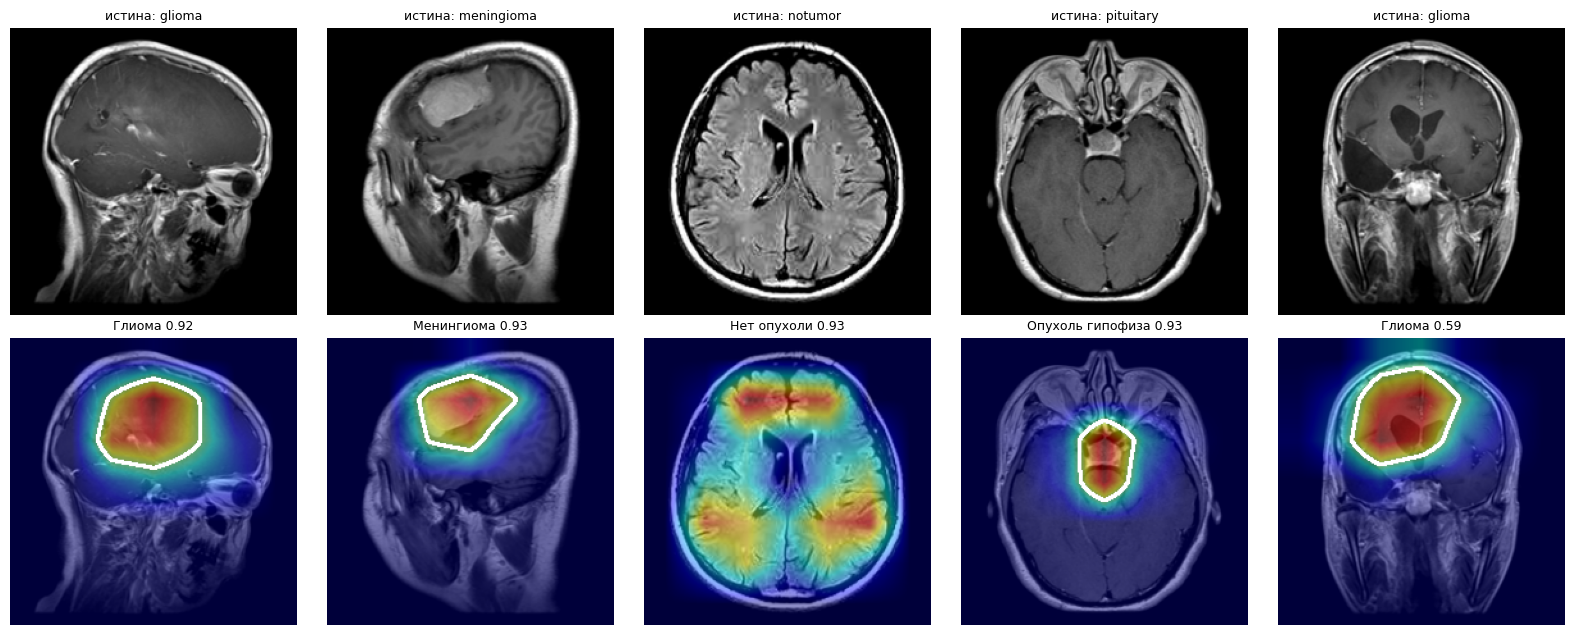

In [6]:
import gradio_app
import matplotlib.pyplot as plt
from PIL import Image

picks = []
for cl in P.classes:
    d = te[(te.cls == cl) & correct_te]
    picks.append(d.sample(1, random_state=3).index[0])
picks.append(te.index[int(np.argmax(dist_te))])

fig, axs = plt.subplots(2, len(picks), figsize=(3.2 * len(picks), 6.4))
for j, i in enumerate(picks):
    proc, overlay, label, text = gradio_app.analyze_image(P, np.array(Image.open(sp.loc[i, 'path'])))
    axs[0, j].imshow(proc); axs[1, j].imshow(overlay)
    axs[0, j].set_title(f"истина: {sp.loc[i, 'cls']}", fontsize=9)
    axs[1, j].set_title(max(label, key=label.get)[:18] + f" {max(label.values()):.2f}", fontsize=9)
    print(f"--- {sp.loc[i, 'cls']}:", text.splitlines()[1][:120])
for a in axs.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

In [7]:
EX = Path('/content/examples'); EX.mkdir(exist_ok=True)
for f in EX.glob('*'): f.unlink()
sel = []
for cl in P.classes:
    d = te[(te.cls == cl) & correct_te].sample(2, random_state=5)
    sel += [(i, cl) for i in d.index]
far = np.argsort(-dist_te)[:2]
sel += [(te.index[k], 'нетипичный') for k in far]
examples = []
for n, (i, tag) in enumerate(sel):
    src = Path(sp.loc[i, 'path'])
    dst = EX / f'{n + 1:02d}_{tag}{src.suffix.lower()}'
    shutil.copy(src, dst); examples.append(str(dst))
print(len(examples), 'примеров:', [Path(e).name for e in examples])

10 примеров: ['01_glioma.jpg', '02_glioma.jpg', '03_meningioma.jpg', '04_meningioma.jpg', '05_notumor.jpg', '06_notumor.jpg', '07_pituitary.jpg', '08_pituitary.jpg', '09_нетипичный.jpg', '10_нетипичный.jpg']


## Запуск интерфейса


In [16]:
import io, os
import numpy as np
import ipywidgets as w
from PIL import Image
from IPython.display import clear_output, display, Markdown
import gradio_app

ORANGE = "#e8590c"
cur = {"img": None}

def to_png(arr, max_side=None):
    a = np.asarray(arr)
    if a.dtype != np.uint8:
        a = (np.clip(a, 0, 1) * 255) if a.max() <= 1.0 else np.clip(a, 0, 255)
        a = a.astype(np.uint8)
    im = Image.fromarray(a)
    if max_side:
        im.thumbnail((max_side, max_side))
    buf = io.BytesIO(); im.save(buf, format="PNG")
    return buf.getvalue()

def empty_img(width):
    return w.Image(format="png", width=width)

# ---------- левая колонка ----------
up = w.FileUpload(accept="image/*", multiple=False, description="Загрузить снимок")
prev = empty_img(420)
btn = w.Button(description="Проанализировать", button_style="warning",
               layout=w.Layout(width="420px", height="40px"))

def set_image(img_rgb):
    cur["img"] = np.array(img_rgb)
    prev.value = to_png(cur["img"])

def on_upload(change):
    v = up.value
    if v:
        item = v[0] if isinstance(v, (tuple, list)) else list(v.values())[0]
        set_image(Image.open(io.BytesIO(bytes(item["content"]))).convert("RGB"))
up.observe(on_upload, names="value")

# примеры: миниатюры + кнопки
def make_example(p, i):
    thumb = w.Image(value=to_png(np.array(Image.open(p).convert("RGB")), 90), format="png", width=80)
    b = w.Button(description=str(i + 1), tooltip=os.path.basename(p), layout=w.Layout(width="80px"))
    b.on_click(lambda _, p=p: set_image(Image.open(p).convert("RGB")))
    return w.VBox([thumb, b])

ex_row = w.HBox([make_example(p, i) for i, p in enumerate(examples)],
                layout=w.Layout(flex_flow="row wrap"))

left = w.VBox([w.HTML("<b>Снимок МРТ</b> (jpg или png)"), up, prev, btn,
               w.HTML("<b>Примеры</b> (выберите и нажмите «Проанализировать»)"), ex_row],
              layout=w.Layout(width="440px"))

# ---------- правая колонка ----------
probs_html = w.HTML()
report = w.Output()
right = w.VBox([w.HTML("<b>Оценка модели по классам</b>"), probs_html, report],
               layout=w.Layout(width="520px"))

# ---------- нижний ряд ----------
img_proc = empty_img(400)
img_cam = empty_img(400)
bottom = w.HBox([
    w.VBox([w.HTML("<b>Снимок после стандартизации</b> (как его видит модель)"), img_proc]),
    w.VBox([w.HTML("<b>Карта внимания и область интереса</b>"), img_cam]),
], layout=w.Layout(margin="10px 0 0 0"))

def probs_to_html(label):
    items = sorted(label.items(), key=lambda kv: -kv[1])
    html = f"<div style='font-size:22px;font-weight:700;margin:6px 0 10px'>{items[0][0]}</div>"
    for name, p in items:
        html += (f"<div style='margin:4px 0'><div style='display:flex;justify-content:space-between'>"
                 f"<span>{name}</span><span>{p*100:.0f}%</span></div>"
                 f"<div style='background:rgba(128,128,128,.3);height:6px;border-radius:3px'>"
                 f"<div style='background:{ORANGE};width:{p*100:.1f}%;height:6px;border-radius:3px'></div></div></div>")
    return html

def on_click(_):
    with report:
        clear_output(wait=True)
        if cur["img"] is None:
            print("Сначала выберите пример или загрузите снимок"); return
        proc, cam, label, text = gradio_app.analyze_image(P, cur["img"])
        if proc is None:
            display(Markdown(text)); return
        probs_html.value = probs_to_html(label)
        img_proc.value = to_png(proc)
        img_cam.value = to_png(cam)
        display(Markdown(text))
btn.on_click(on_click)

# ---------- сборка ----------
display(w.VBox([
    w.HTML("<h2>Прототип: поддержка анализа МРТ головного мозга</h2>"),
    w.HTML("<i>Исследовательский прототип, <b>не является медицинским изделием</b> и не ставит диагноз. "
           "Результат — вспомогательная подсказка для врача, окончательное решение принимает специалист.</i>"),
    w.HBox([left, right]),
    bottom,
    w.HTML("<small><b>Данные.</b> При локальном запуске снимки не покидают компьютер. "
           "Используйте только обезличенные демонстрационные снимки.</small>"),
]))